# UCS420 · Cognitive Computing · Assignment 10
## Diabetes Care Information Assistant
#1024170375 (odd)





## 1. Setup

In [17]:
!pip install -q nltk scikit-learn pandas matplotlib seaborn networkx ipywidgets

In [18]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
print("Setup complete")

Setup complete


## 2. Labelled corpus
**8 intents × 20 queries = 160 labelled queries.** The `emergency` intent lets the classifier also learn emergency wording (a rule layer double-checks it later).

In [19]:
CORPUS = {
    "symptoms_diagnosis": [
        "what are the early symptoms of diabetes",
        "why do i feel very thirsty and urinate frequently",
        "is blurred vision a sign of high blood sugar",
        "how is type 2 diabetes diagnosed",
        "what is the difference between type 1 and type 2 diabetes",
        "what does the hba1c test tell about diabetes",
        "my feet feel numb and tingly is it diabetes",
        "what is prediabetes and how is it detected",
        "what are the warning signs of type 1 diabetes in children",
        "which blood test confirms diabetes",
        "why do my wounds take so long to heal",
        "is feeling tired all the time a symptom of diabetes",
        "what are the signs and symptoms of high blood sugar",
        "how do i know if i have diabetes",
        "what is the fasting glucose value that confirms diabetes",
        "do frequent urination and excessive hunger mean diabetes",
        "what are the symptoms of gestational diabetes",
        "what is the oral glucose tolerance test",
        "what is the diagnosis criteria for prediabetes",
        "can diabetes cause tiredness and constant hunger",
    ],
    "diet_nutrition": [
        "what foods should a diabetic person eat",
        "can i eat rice if i have diabetes",
        "which fruits are safe for diabetes patients",
        "how many carbohydrates should i have per meal",
        "is sugar free sweetener safe for diabetics",
        "what is a good breakfast for blood sugar control",
        "can i eat roti and dal with diabetes",
        "what is the glycemic index of foods",
        "which vegetables are good for a diabetic diet",
        "can diabetics eat sweets or mithai during festivals",
        "is milk or curd okay for a person with diabetes",
        "what snacks can i eat between meals with diabetes",
        "what should a diabetic eat for lunch and dinner",
        "which food items raise blood sugar the most",
        "is brown rice better than white rice for diabetes",
        "can diabetic patients drink fruit juice or tea with sugar",
        "what is the best diet plan for type 2 diabetes",
        "how much protein and fibre should a diabetic eat",
        "can i eat bananas and mangoes with diabetes",
        "are nuts and oats good for diabetic people",
    ],
    "medication_insulin": [
        "how does metformin work",
        "what are the side effects of metformin",
        "when should i take insulin",
        "how do i inject insulin correctly",
        "what are the different types of insulin",
        "how should insulin be stored",
        "do i need to take diabetes tablets every day",
        "what happens if i miss a dose of my medicine",
        "what is the best time to take metformin tablets",
        "which injection sites are best for insulin",
        "what are sulfonylurea tablets used for",
        "does insulin cause weight gain",
        "what are the common medicines for type 2 diabetes",
        "how long does insulin take to start working",
        "can metformin cause stomach upset or diarrhoea",
        "what is basal and bolus insulin",
        "where can i inject insulin on my body",
        "how do i carry an insulin pen while travelling",
        "what is an insulin pump",
        "are there any side effects of diabetes tablets",
    ],
    "glucose_monitoring": [
        "how often should i check my blood sugar",
        "what is a normal fasting blood glucose level",
        "what is the target blood sugar after meals",
        "how do i use a glucometer",
        "what is a continuous glucose monitor",
        "what should my hba1c be",
        "when is the best time to test blood sugar",
        "what is a good blood sugar range for diabetics",
        "how do i keep a record of my blood sugar readings",
        "what is a normal random blood sugar level",
        "how accurate are home glucose meters",
        "what is the ideal postprandial glucose value",
        "what is a healthy blood glucose reading before breakfast",
        "how many times a day should a diabetic test sugar",
        "how do i calibrate a glucose meter",
        "what is the normal range of hba1c",
        "how often should i do an hba1c test",
        "is a fingerstick test painful and how do i do it",
        "what number on my glucose meter is too high",
        "what is the difference between fasting and postprandial glucose",
    ],
    "lifestyle_exercise": [
        "how much exercise should a diabetic do",
        "is walking good for diabetes",
        "can yoga help control blood sugar",
        "how does stress affect blood sugar levels",
        "does lack of sleep raise blood sugar",
        "can i fast with diabetes",
        "is it safe to drink alcohol with diabetes",
        "how can i lose weight to manage diabetes",
        "which exercises are best for type 2 diabetes",
        "is it safe to exercise when my sugar is high",
        "does smoking affect diabetes control",
        "how many hours should a diabetic sleep",
        "what type of workout is best for diabetics",
        "how long should i walk every day to control sugar",
        "can meditation or pranayama reduce blood sugar",
        "does being overweight affect diabetes and how can i reduce weight",
        "is it okay to skip meals or do intermittent fasting with diabetes",
        "how does drinking alcohol or smoking affect blood sugar",
        "can poor sleep and tension increase sugar levels",
        "what daily habits help control diabetes",
    ],
    "complications_prevention": [
        "how can diabetes damage my kidneys",
        "how do i prevent diabetic foot ulcers",
        "can diabetes cause eye problems",
        "how to prevent complications of diabetes",
        "what is diabetic neuropathy",
        "how often should i get my eyes checked",
        "does diabetes increase the risk of heart disease",
        "can type 2 diabetes be prevented or reversed",
        "can high sugar cause kidney failure",
        "how often should i check my feet for wounds",
        "what is diabetic retinopathy",
        "how does diabetes affect blood pressure and cholesterol",
        "how does diabetes affect the heart and arteries",
        "what are the long term complications of diabetes",
        "how can i protect my eyes and vision if i have diabetes",
        "what causes diabetic foot and how to care for feet",
        "what tests detect kidney damage in diabetes",
        "how can i avoid nerve damage from diabetes",
        "can diabetes lead to stroke or amputation",
        "how can i reduce the risk of getting type 2 diabetes",
    ],
    "hypo_hyper_management": [
        "what should i do if my blood sugar is low",
        "how to treat mild hypoglycemia at home",
        "what causes high blood sugar in the morning",
        "how can i bring down high blood sugar quickly",
        "what are the signs of hypoglycemia",
        "what is the 15 15 rule for low sugar",
        "why is my sugar high even after taking medicine",
        "what is dawn phenomenon",
        "what should i eat when my sugar drops suddenly",
        "why do i get shaky and sweaty when sugar is low",
        "how do i lower blood sugar naturally when it is high",
        "what causes hypoglycemia at night",
        "what are the symptoms of low blood sugar",
        "how do i raise my blood sugar fast when it is low",
        "what should i do when blood sugar is too high",
        "why does my sugar drop after exercise",
        "what is hypoglycemia unawareness",
        "what are the causes of high blood sugar levels",
        "how much juice should i drink to treat low sugar",
        "why does my sugar spike after meals",
    ],
    "emergency": [
        "my father has diabetes and is unconscious and not responding",
        "i have chest pain and my sugar is very high",
        "my blood sugar is below 40 and i feel confused",
        "i am having a seizure and i am diabetic",
        "fruity smelling breath with continuous vomiting and high sugar",
        "i feel extremely drowsy and my sugar reading is above 500",
        "diabetic patient fainted and is not waking up",
        "i have severe shortness of breath and cannot stop vomiting",
        "my diabetic mother is not breathing properly and is unresponsive",
        "i collapsed and my sugar is extremely low",
        "my glucose meter shows hi and i am vomiting and very sleepy",
        "i am diabetic and feel crushing chest pain",
        "my diabetic father is having a seizure",
        "diabetic patient is unconscious what should i do",
        "i have chest pain and sweating and i am diabetic",
        "my sugar is extremely high and i am vomiting and breathing fast",
        "my child with type 1 diabetes is not waking up",
        "i smell fruity and feel very confused and weak",
        "my husband collapsed and he is diabetic",
        "i cannot breathe properly and my sugar is very high",
    ],
}

rows = [(q, intent) for intent, qs in CORPUS.items() for q in qs]
df = pd.DataFrame(rows, columns=["query", "intent"])
print(f"Total labelled queries: {len(df)} | intents: {df.intent.nunique()}")
df.intent.value_counts().rename("queries").to_frame()

Total labelled queries: 160 | intents: 8


,queries
intent,
symptoms_diagnosis,20
diet_nutrition,20
medication_insulin,20
glucose_monitoring,20
lifestyle_exercise,20
complications_prevention,20
hypo_hyper_management,20
emergency,20


## 3. Hierarchical taxonomy
4 major categories, each with 2 sub-categories; every classifier intent is mapped to a leaf.

In [20]:
TAXONOMY = {
    "Disease Knowledge": {
        "Symptoms & Diagnosis": ["symptoms_diagnosis"],
        "Types & Risk Factors": [],           # covered through the symptoms/diagnosis KB entries
    },
    "Nutrition & Lifestyle": {
        "Diet & Nutrition": ["diet_nutrition"],
        "Exercise & Daily Habits": ["lifestyle_exercise"],
    },
    "Treatment & Monitoring": {
        "Medication & Insulin": ["medication_insulin"],
        "Glucose Monitoring": ["glucose_monitoring"],
    },
    "Complications & Emergencies": {
        "Long-term Complications": ["complications_prevention"],
        "Acute Sugar Problems & Emergencies": ["hypo_hyper_management", "emergency"],
    },
}

def print_taxonomy(tax):
    print("Diabetes Care Taxonomy")
    cats = list(tax.items())
    for i, (cat, subs) in enumerate(cats):
        print(("└── " if i == len(cats) - 1 else "├── ") + cat)
        pre = "    " if i == len(cats) - 1 else "│   "
        sub_items = list(subs.items())
        for j, (sub, intents) in enumerate(sub_items):
            tag = ", ".join(intents) if intents else "(covered by knowledge-base entries)"
            print(pre + ("└── " if j == len(sub_items) - 1 else "├── ") + f"{sub}  →  [{tag}]")

print_taxonomy(TAXONOMY)
INTENT_TO_CATEGORY = {i: c for c, subs in TAXONOMY.items() for s, ins in subs.items() for i in ins}

Diabetes Care Taxonomy
├── Disease Knowledge
│   ├── Symptoms & Diagnosis  →  [symptoms_diagnosis]
│   └── Types & Risk Factors  →  [(covered by knowledge-base entries)]
├── Nutrition & Lifestyle
│   ├── Diet & Nutrition  →  [diet_nutrition]
│   └── Exercise & Daily Habits  →  [lifestyle_exercise]
├── Treatment & Monitoring
│   ├── Medication & Insulin  →  [medication_insulin]
│   └── Glucose Monitoring  →  [glucose_monitoring]
└── Complications & Emergencies
    ├── Long-term Complications  →  [complications_prevention]
    └── Acute Sugar Problems & Emergencies  →  [hypo_hyper_management, emergency]


## 4. Domain concepts and relationships
13 concepts and 16 relationships, stored as (subject, relation, object) triples and drawn as a knowledge graph.

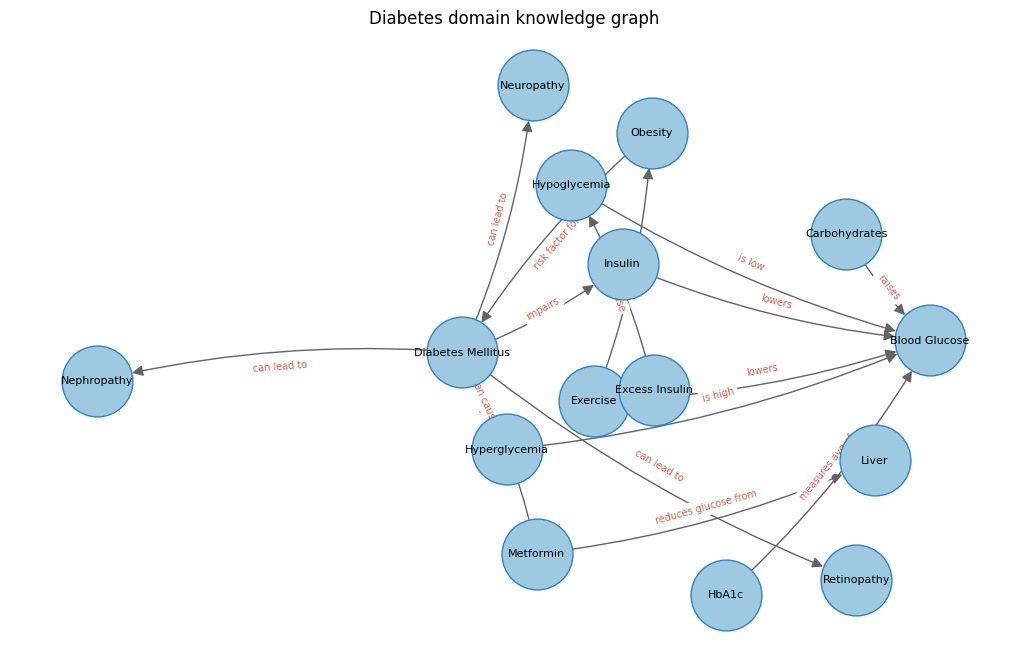

,Subject,Relation,Object
0,Diabetes Mellitus,impairs,Insulin
1,Insulin,lowers,Blood Glucose
2,HbA1c,measures avg of,Blood Glucose
3,Metformin,treats,Diabetes Mellitus
4,Carbohydrates,raises,Blood Glucose
5,Exercise,lowers,Blood Glucose
6,Hypoglycemia,is low,Blood Glucose
7,Hyperglycemia,is high,Blood Glucose
8,Excess Insulin,can cause,Hypoglycemia
9,Diabetes Mellitus,can cause,Hyperglycemia


In [21]:
CONCEPTS = ["Diabetes Mellitus", "Insulin", "Blood Glucose", "HbA1c", "Metformin",
            "Carbohydrates", "Exercise", "Hypoglycemia", "Hyperglycemia", "Neuropathy",
            "Nephropathy", "Retinopathy", "Obesity"]

RELATIONSHIPS = [
    ("Diabetes Mellitus", "impairs", "Insulin"),
    ("Insulin", "lowers", "Blood Glucose"),
    ("HbA1c", "measures avg of", "Blood Glucose"),
    ("Metformin", "treats", "Diabetes Mellitus"),
    ("Carbohydrates", "raises", "Blood Glucose"),
    ("Exercise", "lowers", "Blood Glucose"),
    ("Hypoglycemia", "is low", "Blood Glucose"),
    ("Hyperglycemia", "is high", "Blood Glucose"),
    ("Excess Insulin", "can cause", "Hypoglycemia"),
    ("Diabetes Mellitus", "can cause", "Hyperglycemia"),
    ("Diabetes Mellitus", "can lead to", "Neuropathy"),
    ("Diabetes Mellitus", "can lead to", "Nephropathy"),
    ("Diabetes Mellitus", "can lead to", "Retinopathy"),
    ("Obesity", "risk factor for", "Diabetes Mellitus"),
    ("Exercise", "helps reduce", "Obesity"),
    ("Metformin", "reduces glucose from", "Liver"),
]
assert len(set(CONCEPTS)) >= 8 and len(RELATIONSHIPS) >= 10

G = nx.DiGraph()
for s, r, o in RELATIONSHIPS:
    G.add_edge(s, o, label=r)

plt.figure(figsize=(13, 8))
pos = nx.spring_layout(G, seed=7, k=1.1)
nx.draw_networkx_nodes(G, pos, node_color="#9ecae1", node_size=2600, edgecolors="#3182bd")
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, arrowstyle="-|>", arrowsize=16, edge_color="#636363",
                       node_size=2600, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"),
                             font_size=7, font_color="#d6604d")
plt.title("Diabetes domain knowledge graph"); plt.axis("off"); plt.show()

pd.DataFrame(RELATIONSHIPS, columns=["Subject", "Relation", "Object"])

## 5. NLP preprocessing
Pipeline: **lowercase → tokenisation → stop-word removal → lemmatisation**.

Standard NLTK stop-words are used, except negations/position words (`not, no, before, after, above, below, over, under, up, down`) which are kept because they change meaning in this domain (*"sugar **after** meals"* vs *"**before** meals"*).

In [22]:
lemmatizer = WordNetLemmatizer()
KEEP = {"not", "no", "before", "after", "above", "below", "over", "under", "up", "down"}
STOP = set(stopwords.words("english")) - KEEP

def preprocess(text, return_steps=False):
    lowered = text.lower()                                   # 1. lowercase
    lowered = re.sub(r"[/\-]", " ", lowered)                 #    mg/dl -> mg dl
    tokens = word_tokenize(lowered)                          # 2. tokenisation
    tokens = [t for t in tokens if t.isalnum()]              #    drop punctuation
    no_stop = [t for t in tokens if t not in STOP]           # 3. stop-word removal
    lemmas = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "n"), "v") for t in no_stop]  # 4. lemmatisation
    if return_steps:
        return {"lowercase": lowered, "tokens": tokens, "no_stopwords": no_stop, "lemmas": lemmas}
    return " ".join(lemmas)

demo = "My feet are feeling numb, and I was checking my Blood Sugar AFTER eating meals!"
for step, out in preprocess(demo, return_steps=True).items():
    print(f"{step:13s}: {out}")

df["clean"] = df["query"].apply(preprocess)
df.head(8)

lowercase    : my feet are feeling numb, and i was checking my blood sugar after eating meals!
tokens       : ['my', 'feet', 'are', 'feeling', 'numb', 'and', 'i', 'was', 'checking', 'my', 'blood', 'sugar', 'after', 'eating', 'meals']
no_stopwords : ['feet', 'feeling', 'numb', 'checking', 'blood', 'sugar', 'after', 'eating', 'meals']
lemmas       : ['foot', 'feel', 'numb', 'check', 'blood', 'sugar', 'after', 'eat', 'meal']


,query,intent,clean
0,what are the early symptoms of diabetes,symptoms_diagnosis,early symptom diabetes
1,why do i feel very thirsty and urinate frequently,symptoms_diagnosis,feel thirsty urinate frequently
2,is blurred vision a sign of high blood sugar,symptoms_diagnosis,blur vision sign high blood sugar
3,how is type 2 diabetes diagnosed,symptoms_diagnosis,type 2 diabetes diagnose
4,what is the difference between type 1 and type 2 diabetes,symptoms_diagnosis,difference type 1 type 2 diabetes
5,what does the hba1c test tell about diabetes,symptoms_diagnosis,hba1c test tell diabetes
6,my feet feel numb and tingly is it diabetes,symptoms_diagnosis,foot feel numb tingly diabetes
7,what is prediabetes and how is it detected,symptoms_diagnosis,prediabetes detect


## 6. TF-IDF features and classifier training
Three classifiers are compared with stratified 5-fold cross-validation on the training split; the best probabilistic model (Naive Bayes or Logistic Regression) is deployed, because the low-confidence rule needs class probabilities.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=42)

def make_vec():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

vec = make_vec()
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)
print("TF-IDF matrix (train):", Xtr.shape)

candidates = {
    "Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(C=50, max_iter=3000),
    "Linear SVM": LinearSVC(C=1.0),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, clf in candidates.items():
    s = cross_val_score(clf, Xtr, y_train, cv=skf, scoring="accuracy")
    cv_scores[name] = s.mean()
    print(f"{name:20s} CV accuracy = {s.mean():.3f} (± {s.std():.3f})")

# The assistant needs class probabilities (for the low-confidence rule), so the deployed model is the better
# of the two probabilistic classifiers. Linear SVM is reported for comparison only.
model_name = max(["Naive Bayes", "Logistic Regression"], key=cv_scores.get)
print("\nSelected model:", model_name)

TF-IDF matrix (train): (120, 571)
Naive Bayes          CV accuracy = 0.700 (± 0.100)
Logistic Regression  CV accuracy = 0.675 (± 0.089)
Linear SVM           CV accuracy = 0.675 (± 0.096)

Selected model: Naive Bayes


## 7. Evaluation

Accuracy  : 0.725
Precision : 0.744 (weighted)
Recall    : 0.725 (weighted)
F1-score  : 0.714 (weighted)

                          precision    recall  f1-score   support

complications_prevention       0.67      0.80      0.73         5
          diet_nutrition       0.83      1.00      0.91         5
               emergency       0.83      1.00      0.91         5
      glucose_monitoring       0.75      0.60      0.67         5
   hypo_hyper_management       0.60      0.60      0.60         5
      lifestyle_exercise       0.60      0.60      0.60         5
      medication_insulin       0.67      0.80      0.73         5
      symptoms_diagnosis       1.00      0.40      0.57         5

                accuracy                           0.72        40
               macro avg       0.74      0.73      0.71        40
            weighted avg       0.74      0.72      0.71        40



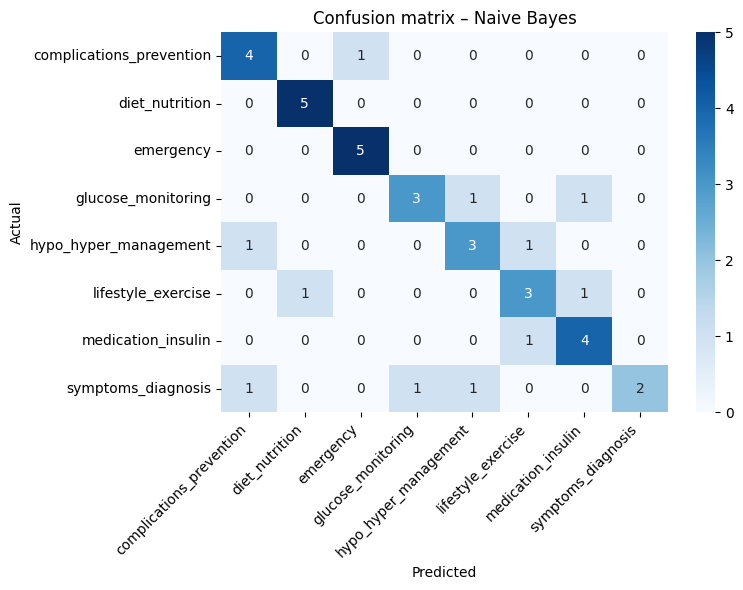

In [24]:
model = candidates[model_name].fit(Xtr, y_train)
y_pred = model.predict(Xte)

acc = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
print(f"Accuracy  : {acc:.3f}")
print(f"Precision : {p:.3f} (weighted)")
print(f"Recall    : {r:.3f} (weighted)")
print(f"F1-score  : {f1:.3f} (weighted)\n")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(df["intent"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix – {model_name}")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

In [25]:
# Final deployment model: re-train on ALL labelled data (evaluation above used the held-out split)
final_vec = make_vec()
X_all = final_vec.fit_transform(df["clean"])
from sklearn.base import clone
final_model = clone(candidates[model_name]).fit(X_all, df["intent"])
VOCAB = set(final_vec.vocabulary_)
print("Deployment model trained on", len(df), "queries")

Deployment model trained on 160 queries


## 8. Domain knowledge base
Each intent has several entries. At run time the assistant retrieves the entry whose text is **most similar (TF-IDF cosine)** to the user's query within the predicted intent.

In [26]:
KB = {
 "symptoms_diagnosis": [
  ("Early symptoms of diabetes",
   "Common early signs are increased thirst, frequent urination, constant hunger, tiredness, blurred vision, slow healing of cuts and wounds, unexplained weight loss and tingling or numbness in hands and feet. Type 2 diabetes can develop slowly, so symptoms are often mild or missed."),
  ("How diabetes is diagnosed",
   "Diabetes is diagnosed with blood tests: fasting plasma glucose of 126 mg/dL or more, HbA1c of 6.5% or more, a 2-hour glucose of 200 mg/dL or more in an oral glucose tolerance test, or a random glucose of 200 mg/dL or more with classic symptoms. Results normally need confirmation by a repeat test."),
  ("Prediabetes",
   "Prediabetes means sugar is higher than normal but not yet in the diabetes range: fasting glucose 100-125 mg/dL or HbA1c 5.7-6.4%. Weight loss, regular physical activity and healthy eating can often prevent progression to type 2 diabetes."),
  ("Type 1 vs type 2 diabetes",
   "Type 1 is an autoimmune condition in which the body makes little or no insulin, so insulin therapy is always needed. Type 2 is the more common form, where the body resists insulin or does not make enough; it is managed with lifestyle changes, tablets and sometimes insulin. Gestational diabetes occurs during pregnancy."),
  ("HbA1c test",
   "HbA1c reflects your average blood sugar over the last 2-3 months. Below 5.7% is normal, 5.7-6.4% is prediabetes and 6.5% or above indicates diabetes. It does not need fasting."),
  ("Numbness, tingling, blurred vision and weight loss",
   "Numb or tingling feet, blurred vision and unexplained weight loss can be signs of high blood sugar or nerve damage, but they also have other causes. They are not enough to diagnose diabetes; get a fasting glucose or HbA1c test from a doctor or lab."),
 ],
 "diet_nutrition": [
  ("Healthy plate for diabetes",
   "Fill half the plate with non-starchy vegetables, a quarter with protein such as dal, paneer, eggs, fish or chicken, and a quarter with whole-grain carbohydrates. Choose whole grains, pulses, nuts and seeds, and limit sugary drinks, sweets, fried and ultra-processed foods."),
  ("Rice, roti and dal",
   "People with diabetes can eat rice and roti in controlled portions. Prefer whole wheat, millet (ragi, jowar, bajra) or brown rice, keep the portion modest, and pair it with dal, vegetables and curd or salad. Fibre and protein slow the rise in sugar."),
  ("Fruits",
   "Whole fruits in sensible portions are fine: guava, apple, pear, papaya, berries and oranges are good choices. Avoid fruit juice, and take larger-sugar fruits such as mango, banana, grapes and chikoo in small portions."),
  ("Carbohydrate counting",
   "Carbohydrates raise blood sugar the most. Many adults aim for roughly 45-60 g of carbohydrate per meal, but the right amount depends on your medicines, weight and activity, so ask a doctor or dietitian for a personal target."),
  ("Sweeteners and sugar-free products",
   "Approved non-nutritive sweeteners such as stevia, sucralose and aspartame do not raise blood sugar and are generally safe in moderation. 'Sugar-free' foods can still contain carbohydrates and fat, so read the label."),
  ("Breakfast ideas",
   "Good breakfasts combine protein, fibre and slow carbohydrates: vegetable besan chilla, moong dal chilla, oats with nuts, eggs with whole-grain toast, or vegetable poha with sprouts. Avoid sweetened cereals, white bread with jam and fruit juice."),
  ("Glycemic index",
   "The glycemic index (GI) ranks carbohydrate foods by how quickly they raise blood sugar. Low-GI foods (55 or less) such as oats, legumes, most vegetables and many fruits cause a slower rise than high-GI foods such as white bread, potatoes and sugary drinks. Portion size matters as well."),
 ],
 "medication_insulin": [
  ("How metformin works",
   "Metformin lowers blood sugar mainly by reducing the amount of glucose made by the liver and by improving how the body responds to insulin. It is usually the first tablet prescribed for type 2 diabetes and is typically taken with meals."),
  ("Metformin side effects",
   "Common side effects are nausea, stomach upset, diarrhoea, gas and a metallic taste, which often ease with time or with an extended-release tablet. Long-term use can lower vitamin B12. Rarely it causes lactic acidosis, so tell your doctor about kidney problems. Do not stop it without medical advice."),
  ("Types of insulin",
   "Insulin types differ by how fast and how long they act: rapid-acting (taken just before meals), short-acting (regular), intermediate-acting (NPH), long-acting (basal, once daily) and premixed insulins. Your doctor chooses the type and schedule."),
  ("Injecting insulin",
   "Wash your hands, check the insulin and the label, attach a new needle, dial the dose, and inject into fatty tissue (abdomen, thigh or upper arm) at a 90 degree angle. Rotate injection sites, hold the needle in for about 10 seconds and never reuse needles."),
  ("Insulin storage",
   "Keep unopened insulin in a refrigerator (2-8 degrees C) and never freeze it. The vial or pen in use can usually be kept at room temperature for about 28 days, away from heat and sunlight; check the leaflet for your brand. Do not use insulin that looks cloudy when it should be clear."),
  ("Timing of insulin and tablets",
   "Timing depends on the medicine: rapid-acting insulin is taken before meals, long-acting insulin at the same time every day, and many tablets with food. Diabetes medicines are usually taken regularly, not only when sugar is high, so follow your prescription."),
  ("Missed dose",
   "If you miss a dose, do not double the next one. Follow the leaflet or call your doctor or pharmacist, who can tell you whether to take it late or skip it. Check your sugar more often that day."),
 ],
 "glucose_monitoring": [
  ("How often to check sugar",
   "How often depends on your treatment. People on multiple insulin injections often check 4 or more times a day, while those on tablets may check a few times a week or as their doctor advises. Check more often when ill, after medicine changes and before driving or exercise."),
  ("Target glucose ranges",
   "Typical targets for many adults with diabetes are 80-130 mg/dL before meals (fasting) and under 180 mg/dL about 2 hours after starting a meal. In people without diabetes, normal fasting glucose is below 100 mg/dL. Your doctor may set different targets for you."),
  ("HbA1c targets",
   "Many adults with diabetes aim for an HbA1c below 7%, and the test is usually repeated every 3 months if targets are not met and at least twice a year if stable. Targets may be looser for older adults or people at risk of low sugar."),
  ("Using a glucometer",
   "Wash and dry your hands, insert a test strip, prick the side of a fingertip, touch the blood drop to the strip and read the result in a few seconds. Check the strip expiry date and record the reading in a log."),
  ("Continuous glucose monitoring (CGM)",
   "A CGM uses a small sensor under the skin to measure glucose in the fluid between cells every few minutes, showing trends and alerts for highs and lows without repeated finger pricks. It is especially useful for people on insulin."),
  ("Best time to test",
   "Common test times are fasting (on waking), before meals, 2 hours after meals, at bedtime and when you feel symptoms of low or high sugar. Testing at different times builds a picture of how food, medicines and activity affect you."),
 ],
 "lifestyle_exercise": [
  ("Exercise recommendations",
   "Aim for at least 150 minutes a week of moderate activity such as brisk walking, plus muscle-strengthening exercise 2-3 days a week. Avoid sitting for long periods. Check your sugar before and after exercise if you use insulin or sulfonylureas, and carry a fast-acting carbohydrate."),
  ("Walking",
   "Walking is a great start. A 10-15 minute walk after meals can noticeably lower the post-meal rise in blood sugar. Wear proper shoes and check your feet afterwards."),
  ("Yoga and relaxation",
   "Yoga, pranayama and meditation can modestly help blood sugar, blood pressure and stress, but they should add to, not replace, medicines and diet. Avoid extreme postures if you have eye or foot complications."),
  ("Stress and sleep",
   "Stress hormones such as cortisol raise blood sugar, and poor sleep increases insulin resistance. Aim for 7-9 hours of sleep, keep a regular routine and use relaxation techniques."),
  ("Fasting with diabetes",
   "Fasting can cause low or high sugar and dehydration, especially on insulin or sulfonylureas. Talk to your doctor well before a fast so medicines can be adjusted, check sugar frequently and break the fast if sugar goes too low or too high."),
  ("Alcohol",
   "Alcohol can cause delayed low blood sugar, especially on an empty stomach or with insulin. If you drink, keep it moderate (at most one drink a day for women and two for men), eat with it and avoid sugary mixers."),
  ("Weight management",
   "Losing 5-10% of body weight improves blood sugar, blood pressure and cholesterol in type 2 diabetes. Combine portion control, fewer refined carbohydrates, regular activity and sleep, and a gradual target of 0.5-1 kg per week."),
  ("Smoking",
   "Smoking worsens insulin resistance and greatly increases the risk of heart, kidney and nerve complications. Quitting is one of the best things a person with diabetes can do."),
 ],
 "complications_prevention": [
  ("Kidney damage (nephropathy)",
   "Long-standing high sugar and blood pressure damage the tiny filters in the kidneys. Get a urine albumin test and an eGFR blood test at least once a year, keep blood pressure below about 130/80 mmHg and ask your doctor about kidney-protective medicines."),
  ("Foot care",
   "Check your feet every day for cuts, blisters, redness or swelling, wash and dry between the toes, moisturise, wear well-fitting shoes and socks, never walk barefoot and have a foot exam at least yearly. See a doctor quickly for any wound that does not heal."),
  ("Eye problems (retinopathy)",
   "High sugar can damage the retina, leading to blurred vision or blindness. Have a dilated eye examination at diagnosis of type 2 diabetes and at least every 1-2 years afterwards, or as advised by your eye doctor."),
  ("Preventing complications",
   "Keep HbA1c, blood pressure and cholesterol within target, do not smoke, stay active, eat healthily, take medicines regularly and attend regular check-ups for eyes, kidneys, feet and heart."),
  ("Diabetic neuropathy",
   "Diabetic neuropathy is nerve damage from long-term high sugar, causing numbness, tingling, burning pain or loss of sensation, most often in the feet and hands. Good sugar control slows it and foot care prevents injuries."),
  ("Heart disease risk",
   "Diabetes roughly doubles the risk of heart attack and stroke. Control blood pressure, cholesterol and sugar, avoid tobacco, exercise regularly and ask your doctor about cholesterol-lowering medicines."),
  ("Preventing or reversing type 2 diabetes",
   "Lifestyle changes such as losing 5-7% of body weight and exercising about 150 minutes a week greatly reduce the chance of getting type 2 diabetes. Some people achieve remission, with normal sugar without medicines, after major weight loss, but it can return, so monitoring is still needed."),
 ],
 "hypo_hyper_management": [
  ("Low blood sugar (hypoglycemia) - what to do",
   "Hypoglycemia means glucose below 70 mg/dL. Symptoms: shakiness, sweating, hunger, fast heartbeat, headache, irritability and confusion. Treat at once with 15 g of fast carbohydrate such as 3-4 glucose tablets, half a cup (about 150 ml) of fruit juice or a tablespoon of sugar, then follow the 15-15 rule."),
  ("The 15-15 rule",
   "Take 15 g of fast-acting carbohydrate, wait 15 minutes, then recheck your sugar. If it is still below 70 mg/dL, repeat. Once it rises above 70, eat a small snack or your next meal to keep it stable."),
  ("High sugar in the morning",
   "Morning highs can be due to the dawn phenomenon (early-morning hormones raise glucose), a late or heavy dinner, too little evening medicine, or rebound after a night low. Check your sugar around 2-3 am for a few days and show the readings to your doctor."),
  ("Dawn phenomenon",
   "The dawn phenomenon is an early-morning rise in blood sugar caused by hormones such as cortisol and growth hormone released before waking. It happens in many people with diabetes; a doctor may adjust timing or dose of medicines."),
  ("Bringing down high sugar",
   "For mild highs: drink water, take a light walk if you feel well and have no ketones, take medicines as prescribed and recheck in a few hours. Do not take extra insulin or tablets without medical advice. Contact your doctor if readings stay above 300 mg/dL or if you have ketones, vomiting or drowsiness."),
  ("Persistent high sugar despite medicine",
   "Sugar can stay high because of illness or infection, stress, missed doses, large carbohydrate portions, low activity, certain steroids or a need to adjust treatment. Keep a log of food, medicine and readings and review it with your doctor."),
 ],
 "emergency": [
  ("Severe low blood sugar (hypoglycemia) emergency",
   "If the person is unconscious, having a seizure, or cannot swallow safely: do NOT give food or drink by mouth. Place them on their side, give glucagon if available and you know how, and call an ambulance immediately (112 or 108 in India). If they are awake and able to swallow, give 15 g of fast sugar and recheck after 15 minutes."),
  ("High sugar with ketones (DKA) emergency",
   "Very high sugar with vomiting, stomach pain, fruity breath, fast deep breathing, drowsiness or confusion may be diabetic ketoacidosis, which is life-threatening. Go to the nearest emergency department immediately or call 112 / 108; do not wait for it to settle."),
  ("General diabetes emergency",
   "Chest pain, severe shortness of breath, fainting, sudden weakness on one side, confusion or an unresponsive person need emergency help. Call 112 or 108 right away, stay with the person and tell responders that the person has diabetes and which medicines they take."),
 ],
}
for intent, entries in KB.items():
    print(f"{intent:26s} {len(entries)} entries")

# one TF-IDF index per intent for retrieval
KB_INDEX = {}
for intent, entries in KB.items():
    docs = [preprocess(t + " " + body) for t, body in entries]
    v = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
    KB_INDEX[intent] = (v, v.fit_transform(docs))

def retrieve(intent, query, top_k=2):
    v, M = KB_INDEX[intent]
    sims = cosine_similarity(v.transform([preprocess(query)]), M).ravel()
    order = sims.argsort()[::-1][:top_k]
    return [(KB[intent][i][0], KB[intent][i][1], float(sims[i])) for i in order]

symptoms_diagnosis         6 entries
diet_nutrition             7 entries
medication_insulin         7 entries
glucose_monitoring         6 entries
lifestyle_exercise         8 entries
complications_prevention   7 entries
hypo_hyper_management      6 entries
emergency                  3 entries


## 9. Reasoning rules
Seven rules run **before / after** the classifier:

| # | Rule | Trigger | Action |
|---|---|---|---|
| R1 | **Emergency escalation** | emergency phrases (unconscious, seizure, fainted, fruity breath, chest pain …) | urgent message + first-aid knowledge, call 112 / 108 |
| R2 | **Critical glucose value** | a reading < 54 or > 400 mg/dL in the query | emergency escalation |
| R3 | **Glucose-reading interpreter** | any other reading in the query | classify the value (low / normal / high …) with advice |
| R4 | **Personal dosage safety** | asks for / wants to change a dose or stop medicine | no dose advice; refer to doctor or pharmacist |
| R5 | **Unsupported query** | non-diabetes health topic (cancer, COVID, migraine …) or out-of-domain text | polite scope message |
| R6 | **Low-confidence handling** | top probability < 0.35, or the two best intents are almost tied | ask the user to rephrase, offer topics |
| R7 | **Greeting / small talk** | hello, thanks, bye | friendly reply and help menu |

In [27]:
CONFIDENCE_THRESHOLD = 0.35   # minimum top-class probability
MARGIN_THRESHOLD = 0.05       # minimum gap between best and second-best intent

EMERGENCY_PATTERNS = [
    r"unconscious|unresponsive|not responding|not waking|won'?t wake|passed out|collaps",
    r"faint(ed|ing)?\b",
    r"seizure|convuls",
    r"fruity",
    r"chest pain|chest tightness",
    r"(severe|extreme)\s+(shortness of breath|breathing)|cannot breathe|can'?t breathe|difficulty breathing",
    r"stroke|face drooping|slurred speech",
    r"(continuous|non[- ]?stop|cannot stop|can'?t stop|persistent)\s+vomit",
    r"vomit\w*.*(high sugar|ketone)|(high sugar|ketone).*vomit",
]
DIABETES_TERMS = {"diabetes", "diabetic", "sugar", "glucose", "insulin", "metformin", "hba1c",
                  "glucometer", "carb", "carbohydrate", "hypoglycemia", "hyperglycemia",
                  "hypo", "hyper", "glycemic", "ketone", "neuropathy", "prediabetes", "cgm"}
UNSUPPORTED_TOPICS = ["cancer", "covid", "corona", "flu", "fever", "cold and cough", "cough", "headache",
                      "migraine", "asthma", "tooth", "dental", "acne", "skin rash", "hair fall", "hair loss",
                      "thyroid", "pregnan", "depress", "anxiety", "arthritis", "back pain", "malaria",
                      "dengue", "tuberculosis", "hepatitis", "kidney stone", "hypertension", "heart attack",
                      "cholesterol", "fracture", "allergy", "vaccin"]
DOSE_PATTERN = (r"\b(how many|how much)\s+(units?|mg|tablets?|insulin|metformin|medicine)\b|"
                r"\bwhat\s+(dose|dosage)\b|\bdose\s+should\s+i\b|\bdosage\b|"
                r"\b(increase|decrease|reduce|change|stop|skip|double|adjust)\b.{0,25}\b(dose|insulin|medicine|medication|tablets?|metformin)\b")
GREETING_PATTERN = r"^\s*(hi|hello|hey|namaste|good (morning|afternoon|evening)|thanks?|thank you|bye|goodbye)\b[\s!.]*$"
DISCLAIMER = "\n\n_This is general educational information, not medical advice. Please consult your doctor for personal decisions._"
EMERGENCY_HEADER = ("🚨 **This may be a medical emergency.**\n\n"
                    "**Call 112 (or ambulance 108) or go to the nearest emergency department NOW.** Do not wait for this chat.\n\n")

def extract_glucose(q):
    q = q.lower()
    if not re.search(r"sugar|glucose|reading|glucometer|mg\s*/?\s*dl|\bbg\b", q):
        return None
    for m in re.finditer(r"\b(\d{2,3})\b(?!\s*(?:g\b|gm\b|grams?|min|minutes?|units?|years?|yrs?|kg|%|hours?|hrs?|am|pm))", q):
        v = int(m.group(1))
        if 20 <= v <= 900:
            return v
    return None

def interpret_glucose(v):
    if v < 54:      return "very low"
    if v < 70:      return "low"
    if v < 100:     return "normal"
    if v < 126:     return "slightly high"
    if v <= 180:    return "above target"
    if v <= 300:    return "high"
    if v <= 400:    return "very high"
    return "dangerously high"

def has_diabetes_term(tokens):
    return any(t in DIABETES_TERMS for t in tokens.split())

## 10. Integrated assistant
`DiabetesAssistant.respond()` chains: **preprocessing (NLP) → rules R7/R1/R2/R3/R4/R5 → intent classification → R6 confidence check → knowledge retrieval → response**.

In [28]:
class DiabetesAssistant:
    def __init__(self, vec, model, threshold=CONFIDENCE_THRESHOLD):
        self.vec, self.model, self.threshold = vec, model, threshold

    # ---- intent classification -------------------------------------------
    def classify(self, clean):
        X = self.vec.transform([clean])
        proba = self.model.predict_proba(X)[0]
        order = proba.argsort()[::-1]
        top, second = proba[order[0]], proba[order[1]]
        return self.model.classes_[order[0]], float(top), float(top - second)

    # ---- main pipeline -----------------------------------------------------
    def respond(self, query):
        q = query.strip()
        low = q.lower()
        clean = preprocess(q)                                       # NLP
        result = dict(query=q, intent=None, category=None, confidence=None, rule=None, source=None)

        if not q:
            return {**result, "rule": "R6 empty input", "response": "Please type a question about diabetes."}

        # R7 greeting
        if re.match(GREETING_PATTERN, low):
            return {**result, "rule": "R7 greeting", "response":
                    "Hello! 👋 I'm your **Diabetes Care Information Assistant**. Ask me about symptoms, diet, "
                    "medicines & insulin, glucose monitoring, exercise, complications, or low/high sugar."}

        # R1 emergency keywords
        if any(re.search(p, low) for p in EMERGENCY_PATTERNS):
            return self._emergency(result, q, "R1 emergency escalation")

        # R2 / R3 glucose value rules
        g = extract_glucose(q)
        if g is not None:
            level = interpret_glucose(g)
            if level in ("very low", "dangerously high"):
                return self._emergency(result, q, f"R2 critical glucose value ({g} mg/dL)")
            advice = {
                "low": "This is **low** (below 70 mg/dL). Take 15 g of fast-acting sugar (3-4 glucose tablets or ~150 ml juice), recheck in 15 minutes and repeat if still below 70.",
                "normal": "This is within the usual normal range (about 70-99 mg/dL), if it was a fasting reading.",
                "slightly high": "This is slightly above normal. If fasting, 100-125 mg/dL falls in the prediabetes range; after a meal it can be normal. Discuss with your doctor.",
                "above target": "This is above the typical fasting target (80-130 mg/dL) but may be acceptable shortly after eating (target under 180 mg/dL).",
                "high": "This is **high**. Drink water, take your prescribed medicines, avoid sugary food and recheck in a few hours. Contact your doctor if it stays high.",
                "very high": "This is **very high**. Check ketones if you have type 1 diabetes or feel unwell and call your doctor the same day. Go to emergency care if you vomit, have stomach pain, fast breathing or drowsiness.",
            }[level]
            return {**result, "intent": "glucose_monitoring", "category": INTENT_TO_CATEGORY["glucose_monitoring"],
                    "rule": f"R3 glucose-reading interpreter ({g} mg/dL)", "source": "rule-based",
                    "response": f"Your reading of **{g} mg/dL**: {advice}{DISCLAIMER}"}

        # R4 personal dosage safety
        if re.search(DOSE_PATTERN, low):
            return {**result, "intent": "medication_insulin", "category": INTENT_TO_CATEGORY["medication_insulin"],
                    "rule": "R4 dosage safety", "source": "rule-based", "response":
                    "⚠️ I can't recommend or change a **dose** or tell you to stop/skip a medicine, because the right amount "
                    "depends on your weight, kidney function, diet, other medicines and sugar readings. "
                    "Please ask your **doctor or pharmacist**. I can explain how a medicine works, its side effects, "
                    "or how to store and inject insulin if that helps." + DISCLAIMER}

        # R5 unsupported (explicit other-health topic without any diabetes term)
        if any(t in low for t in UNSUPPORTED_TOPICS) and not has_diabetes_term(clean):
            return self._unsupported(result)

        # intent classification
        intent, conf, margin = self.classify(clean)
        result.update(intent=intent, confidence=round(conf, 3), category=INTENT_TO_CATEGORY[intent])

        # R5 unsupported (no known vocabulary at all => out of domain)
        if not any(t in VOCAB for t in clean.split()):
            return self._unsupported(result)

        # classifier says "emergency" but no emergency rule fired: escalate only if the model is confident
        if intent == "emergency" and conf >= 0.60:
            return self._emergency(result, q, f"R1 emergency escalation (classifier, conf {conf:.2f})")

        # R6 low confidence: weak top probability, or two intents almost tied (ambiguous)
        if conf < self.threshold or margin < MARGIN_THRESHOLD or intent == "emergency":
            why = f"conf {conf:.2f} < {self.threshold}" if conf < self.threshold else f"margin {margin:.2f} < {MARGIN_THRESHOLD}"
            return {**result, "rule": f"R6 low confidence ({why})", "source": None, "response":
                    "🤔 I'm not sure I understood that. Could you rephrase or be more specific? "
                    "(If someone is in danger right now, call **112 / 108**.) "
                    "I can help with: **symptoms & diagnosis**, **diet**, **medicines & insulin**, **glucose monitoring**, "
                    "**exercise & lifestyle**, **complications**, and **low/high sugar**."}

        # knowledge retrieval
        hits = retrieve(intent, q, top_k=2)
        best = hits[0]
        body = f"**{best[0]}**\n\n{best[1]}"
        if len(hits) > 1 and hits[1][2] >= 0.6 * best[2] and hits[1][2] > 0.05:
            body += f"\n\n**{hits[1][0]}**\n\n{hits[1][1]}"
        return {**result, "rule": "none (normal flow)", "source": best[0], "response": body + DISCLAIMER}

    def _emergency(self, result, q, rule):
        hits = retrieve("emergency", q, top_k=1)
        return {**result, "intent": "emergency", "category": INTENT_TO_CATEGORY["emergency"], "rule": rule,
                "confidence": 1.0, "source": hits[0][0],
                "response": EMERGENCY_HEADER + f"**{hits[0][0]}**\n\n{hits[0][1]}"}

    def _unsupported(self, result):
        return {**result, "rule": "R5 unsupported query", "source": None, "response":
                "I'm specialised in **diabetes care** only, so I can't answer that reliably. "
                "For other health concerns please speak to a doctor. "
                "You can ask me about diabetes symptoms, diet, insulin, glucose monitoring, exercise or complications."}

assistant = DiabetesAssistant(final_vec, final_model)
print(assistant.respond("what are the side effects of metformin")["response"][:300])

**Metformin side effects**

Common side effects are nausea, stomach upset, diarrhoea, gas and a metallic taste, which often ease with time or with an extended-release tablet. Long-term use can lower vitamin B12. Rarely it causes lactic acidosis, so tell your doctor about kidney problems. Do not stop


## 11. Interactive interface
Type a question and press **Ask** (or press Enter). The chat history keeps every query, so you can ask as many as you like.

In [29]:
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

history = []
box = widgets.Text(placeholder="Ask about diabetes… e.g. 'Can I eat rice?'", layout=widgets.Layout(width="70%"))
ask_btn = widgets.Button(description="Ask", button_style="primary", icon="paper-plane")
clear_btn = widgets.Button(description="Clear chat", icon="trash")
out = widgets.Output(layout=widgets.Layout(border="1px solid #ccc", padding="8px", max_height="520px", overflow_y="auto"))

def render():
    with out:
        clear_output(wait=True)
        for h in history:
            display(Markdown(f"**🧑 You:** {h['query']}"))
            meta = f"`intent: {h['intent']} | confidence: {h['confidence']} | rule: {h['rule']}`"
            display(Markdown(f"**🤖 Assistant:** {h['response']}\n\n{meta}\n\n---"))

def on_ask(_=None):
    q = box.value.strip()
    if not q:
        return
    history.append(assistant.respond(q))
    box.value = ""
    render()

def on_clear(_):
    history.clear()
    render()

ask_btn.on_click(on_ask)
clear_btn.on_click(on_clear)
box.on_submit(on_ask) if hasattr(box, "on_submit") else None
display(widgets.VBox([widgets.HTML("<h3>🩺 Diabetes Care Information Assistant</h3>"), widgets.HBox([box, ask_btn, clear_btn]), out]))

In [30]:
# OPTIONAL: plain console chat (type 'exit' to stop) – use this if the widget does not render
def console_chat():
    print("Diabetes Care Assistant (type 'exit' to quit)")
    while True:
        q = input("\nYou: ")
        if q.strip().lower() in {"exit", "quit"}:
            print("Goodbye!"); break
        r = assistant.respond(q)
        print(f"[intent={r['intent']} | conf={r['confidence']} | rule={r['rule']}]\n{r['response']}")

# console_chat()    # <- uncomment to use

## 12. Testing
Covers the five required test types.

In [31]:
TESTS = [
    # 1. One query for EACH intent (new wording, not in the corpus)
    ("1. Intent coverage", "symptoms_diagnosis",       "what are the warning signs that someone might have diabetes"),
    ("1. Intent coverage", "diet_nutrition",           "what should i avoid eating if i have diabetes"),
    ("1. Intent coverage", "medication_insulin",       "what are the common side effects of insulin injections"),
    ("1. Intent coverage", "glucose_monitoring",       "how do i read my glucose meter"),
    ("1. Intent coverage", "lifestyle_exercise",       "is exercise helpful for controlling diabetes"),
    ("1. Intent coverage", "complications_prevention", "how do i protect my feet from diabetic wounds"),
    ("1. Intent coverage", "hypo_hyper_management",    "what do i do when sugar drops too low"),
    ("1. Intent coverage", "emergency",                "my diabetic grandfather is unconscious and not responding"),
    # 2. Differently worded query
    ("2. Different wording", "symptoms_diagnosis",     "what signs should make me suspect diabetes"),
    ("2. Different wording", "medication_insulin",     "tell me how metformin tablets act in the body"),
    ("2. Different wording", "diet_nutrition",         "what can a diabetic person eat for dinner"),
    # 3. Unsupported healthcare query
    ("3. Unsupported", "unsupported",                  "what is the treatment for breast cancer?"),
    ("3. Unsupported", "unsupported",                  "who will win the cricket world cup?"),
    # 4. Low-confidence query
    ("4. Low confidence", "low_confidence",            "diabetes"),
    ("4. Low confidence", "low_confidence",            "tell me about my sugar"),
    # 5. Emergency-related query
    ("5. Emergency", "emergency",                      "my sugar reading is 35 and i feel very shaky"),
    ("5. Emergency", "emergency",                      "i have fruity breath and continuous vomiting"),
    # extra rule checks
    ("Extra rules", "R3 glucose",                      "my fasting sugar is 160 mg/dl, is that okay?"),
    ("Extra rules", "R4 dosage",                       "how many units of insulin should i take tonight?"),
]

records = []
for group, expected, q in TESTS:
    r = assistant.respond(q)
    records.append({"test": group, "query": q, "expected": expected, "predicted intent": r["intent"],
                    "confidence": r["confidence"], "rule fired": r["rule"],
                    "ok?": "✔" if (r["intent"] == expected or expected in str(r["rule"]) or
                                   (expected == "unsupported" and "R5" in str(r["rule"])) or
                                   (expected == "low_confidence" and "R6" in str(r["rule"]))) else "✘"})
results = pd.DataFrame(records)
pd.set_option("display.max_colwidth", 80, "display.width", 200)
results

,test,query,expected,predicted intent,confidence,rule fired,ok?
0,1. Intent coverage,what are the warning signs that someone might have diabetes,symptoms_diagnosis,symptoms_diagnosis,0.790,none (normal flow),✔
1,1. Intent coverage,what should i avoid eating if i have diabetes,diet_nutrition,diet_nutrition,0.375,none (normal flow),✔
2,1. Intent coverage,what are the common side effects of insulin injections,medication_insulin,medication_insulin,0.971,none (normal flow),✔
3,1. Intent coverage,how do i read my glucose meter,glucose_monitoring,glucose_monitoring,0.890,none (normal flow),✔
4,1. Intent coverage,is exercise helpful for controlling diabetes,lifestyle_exercise,lifestyle_exercise,0.839,none (normal flow),✔
5,1. Intent coverage,how do i protect my feet from diabetic wounds,complications_prevention,complications_prevention,0.768,none (normal flow),✔
6,1. Intent coverage,what do i do when sugar drops too low,hypo_hyper_management,hypo_hyper_management,0.917,none (normal flow),✔
7,1. Intent coverage,my diabetic grandfather is unconscious and not responding,emergency,emergency,1.000,R1 emergency escalation,✔
8,2. Different wording,what signs should make me suspect diabetes,symptoms_diagnosis,symptoms_diagnosis,0.629,none (normal flow),✔
9,2. Different wording,tell me how metformin tablets act in the body,medication_insulin,medication_insulin,0.851,none (normal flow),✔


In [32]:
# Full responses for a few representative tests
for q in ["what should i avoid eating if i have diabetes",
          "what is the treatment for breast cancer?",
          "tell me about my sugar",
          "my diabetic grandfather is unconscious and not responding"]:
    r = assistant.respond(q)
    print("="*90, f"\nQ: {q}\n[intent={r['intent']} | conf={r['confidence']} | rule={r['rule']}]\n{r['response']}\n")

Q: what should i avoid eating if i have diabetes
[intent=diet_nutrition | conf=0.375 | rule=none (normal flow)]
**Rice, roti and dal**

People with diabetes can eat rice and roti in controlled portions. Prefer whole wheat, millet (ragi, jowar, bajra) or brown rice, keep the portion modest, and pair it with dal, vegetables and curd or salad. Fibre and protein slow the rise in sugar.

_This is general educational information, not medical advice. Please consult your doctor for personal decisions._

Q: what is the treatment for breast cancer?
[intent=None | conf=None | rule=R5 unsupported query]
I'm specialised in **diabetes care** only, so I can't answer that reliably. For other health concerns please speak to a doctor. You can ask me about diabetes symptoms, diet, insulin, glucose monitoring, exercise or complications.

Q: tell me about my sugar
[intent=symptoms_diagnosis | conf=0.341 | rule=R6 low confidence (conf 0.34 < 0.35)]
🤔 I'm not sure I understood that. Could you rephrase or be 

## 13. Summary
* **Corpus:** 160 labelled queries, 8 intents · **Taxonomy:** 4 categories × 2 sub-categories · **Concepts/relations:** 13 / 16
* **NLP:** lowercase → tokenise → stop-word removal → lemmatise · **Features:** TF-IDF (uni+bigrams)
* **Model:** Naive Bayes vs Logistic Regression vs Linear SVM compared by cross-validation; evaluated with accuracy, precision, recall, F1 and a confusion matrix
* **Reasoning:** 7 rules (emergency escalation, critical-value escalation, glucose interpreter, dosage safety, unsupported query, low confidence, greeting)
* **Knowledge base:** 3-8 entries per intent, retrieved by TF-IDF cosine similarity
* **Deployment:** interactive ipywidgets chat in Google Colab